# Assignment 7: Titanic Dataset
Same idea as the Olympic investigation, but with the Seaborn Titanic dataset.
3 questions answered below using Pandas and Seaborn.

## Load the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_titanic = sns.load_dataset("titanic")
df_titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


## Question 1: What percentage of each class of ship passed away?

In [2]:
# survived = 1 means they lived, so 1 - mean(survived) gives the death rate
death_rate = (1 - df_titanic.groupby("class")["survived"].mean()) * 100
death_rate

class
First     37.037037
Second    52.717391
Third     75.763747
Name: survived, dtype: float64

Third class had the highest death rate.

## Question 2: Did gender affect who survived?

In [3]:
survival_by_sex = df_titanic.groupby("sex")["survived"].mean() * 100
survival_by_sex

sex
female    74.203822
male      18.890815
Name: survived, dtype: float64

Females survived at a much higher rate than males

## Question 3: Which age group had the best chance of surviving?

In [4]:
# Bin ages into groups, then check survival rate per group
df_titanic["age_group"] = pd.cut(df_titanic["age"], bins=[0, 12, 18, 35, 60, 100], labels=["child", "teen", "young adult", "adult", "senior"])

df_titanic.groupby("age_group", observed=True)["survived"].mean() * 100

age_group
child          57.971014
teen           42.857143
young adult    38.268156
adult          40.000000
senior         22.727273
Name: survived, dtype: float64

Children had the best survival odds, risk increased as age increased.

## Survival by class and gender

Combining class and sex to see the full picture.

In [5]:
df_titanic.groupby(["class", "sex"])["survived"].mean() * 100

class   sex   
First   female    96.808511
        male      36.885246
Second  female    92.105263
        male      15.740741
Third   female    50.000000
        male      13.544669
Name: survived, dtype: float64

First class females had the highest survival rate, third class males had the lowest rate.

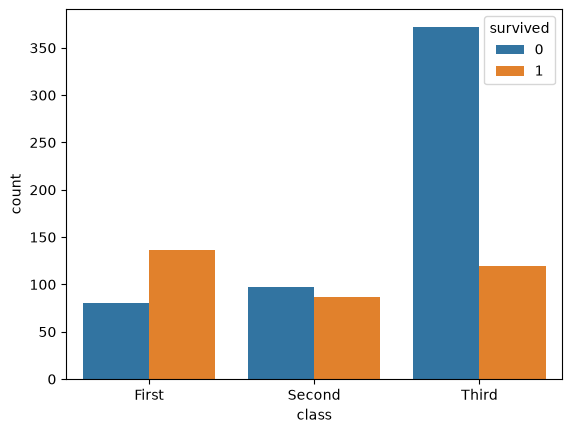

In [6]:

sns.countplot(x="class", hue="survived", data=df_titanic)
plt.show()